# **EDA Project: Airbnb**

### **Import Libraries**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **Load Dataset**

In [5]:
df = pd.read_csv("airbnb.csv")

### **Checking Dataset Informations**

In [6]:
print("Size :", df.size)
print("Shape :", df.shape)

Size : 170323
Shape : (10019, 17)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10019 entries, 0 to 10018
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          10019 non-null  int64  
 1   listing_id          10019 non-null  int64  
 2   name                10014 non-null  str    
 3   host_id             10019 non-null  int64  
 4   host_name           10017 non-null  str    
 5   neighbourhood_full  10019 non-null  str    
 6   coordinates         10019 non-null  str    
 7   room_type           10019 non-null  str    
 8   price               9781 non-null   str    
 9   number_of_reviews   10019 non-null  int64  
 10  last_review         7944 non-null   str    
 11  reviews_per_month   7944 non-null   float64
 12  availability_365    10019 non-null  int64  
 13  rating              7944 non-null   float64
 14  number_of_stays     7944 non-null   float64
 15  5_stars             7944 non-null   float64
 16  listing_added  

In [8]:
df.describe()

,Unnamed: 0,listing_id,host_id,number_of_reviews,reviews_per_month,availability_365,rating,number_of_stays,5_stars
count,10019.000000,1.001900e+04,1.001900e+04,10019.000000,7944.000000,10019.000000,7944.000000,7944.000000,7944.000000
mean,5009.000000,1.927634e+07,6.795923e+07,22.459727,1.353894,112.284260,4.014458,33.991541,0.718599
std,2892.380507,1.095056e+07,7.863106e+07,43.173896,1.615380,131.636043,0.575064,56.089279,0.079978
min,0.000000,3.831000e+03,2.787000e+03,0.000000,0.010000,0.000000,3.000633,1.200000,0.600026
25%,2504.500000,9.674772e+06,7.910880e+06,1.000000,0.200000,0.000000,3.520443,3.600000,0.655576
50%,5009.000000,2.007030e+07,3.165167e+07,5.000000,0.710000,44.000000,4.027965,10.800000,0.709768
75%,7513.500000,2.933864e+07,1.074344e+08,22.000000,2.000000,226.000000,4.516378,38.400000,0.763978
max,10018.000000,3.648724e+07,2.741034e+08,510.000000,16.220000,365.000000,5.181114,612.000000,0.950339


In [9]:
df.head()

,Unnamed: 0,listing_id,name,host_id,host_name,neighbourhood_full,coordinates,room_type,price,number_of_reviews,last_review,reviews_per_month,availability_365,rating,number_of_stays,5_stars,listing_added
0,0,13740704,"Cozy,budget friendly, cable inc, private entra...",20583125,Michel,"Brooklyn, Flatlands","(40.63222, -73.93398)",Private room,45$,10,2018-12-12,0.70,85,4.100954,12.0,0.609432,2018-06-08
1,1,22005115,Two floor apartment near Central Park,82746113,Cecilia,"Manhattan, Upper West Side","(40.78761, -73.96862)",Entire home/apt,135$,1,2019-06-30,1.00,145,3.367600,1.2,0.746135,2018-12-25
2,2,21667615,Beautiful 1BR in Brooklyn Heights,78251,Leslie,"Brooklyn, Brooklyn Heights","(40.7007, -73.99517)",Entire home/apt,150$,0,NaN,NaN,65,NaN,NaN,NaN,2018-08-15
3,3,6425850,"Spacious, charming studio",32715865,Yelena,"Manhattan, Upper West Side","(40.79169, -73.97498)",Entire home/apt,86$,5,2017-09-23,0.13,0,4.763203,6.0,0.769947,2017-03-20
4,4,22986519,Bedroom on the lively Lower East Side,154262349,Brooke,"Manhattan, Lower East Side","(40.71884, -73.98354)",Private room,160$,23,2019-06-12,2.29,102,3.822591,27.6,0.649383,2020-10-23


### **Checking null values**

In [10]:
df.isnull().sum()

Unnamed: 0               0
listing_id               0
name                     5
host_id                  0
host_name                2
neighbourhood_full       0
coordinates              0
room_type                0
price                  238
number_of_reviews        0
last_review           2075
reviews_per_month     2075
availability_365         0
rating                2075
number_of_stays       2075
5_stars               2075
listing_added            0
dtype: int64

### **Creating Copy of Dataset**

In [11]:
copy = df
copy.columns

Index(['Unnamed: 0', 'listing_id', 'name', 'host_id', 'host_name',
       'neighbourhood_full', 'coordinates', 'room_type', 'price',
       'number_of_reviews', 'last_review', 'reviews_per_month',
       'availability_365', 'rating', 'number_of_stays', '5_stars',
       'listing_added'],
      dtype='str')

In [12]:
# Remove first column
copy.drop(columns="Unnamed: 0", inplace=True)

In [13]:
print(copy.isnull().sum())
print(copy.shape)

listing_id               0
name                     5
host_id                  0
host_name                2
neighbourhood_full       0
coordinates              0
room_type                0
price                  238
number_of_reviews        0
last_review           2075
reviews_per_month     2075
availability_365         0
rating                2075
number_of_stays       2075
5_stars               2075
listing_added            0
dtype: int64
(10019, 16)


### **Drop Duplicate and Null Value Rows**

In [14]:
# Drop duplicates rows
copy.drop_duplicates(inplace=True)

In [15]:
# Remove rows which has missing values in name and host_name
copy = copy.dropna(subset=['name','host_name'])

In [16]:
print(copy.isnull().sum())
print(copy.shape)

listing_id               0
name                     0
host_id                  0
host_name                0
neighbourhood_full       0
coordinates              0
room_type                0
price                  238
number_of_reviews        0
last_review           2069
reviews_per_month     2069
availability_365         0
rating                2069
number_of_stays       2069
5_stars               2069
listing_added            0
dtype: int64
(9999, 16)


### **Renaming Columns**

In [17]:
rename = {
    'PRIVATE ROOM' : 'Private Room',
    'Private room room' : 'Private Room',
    'Shared room' : 'Shared Room',
    'Shared room' : 'Shared Room',
    'Entire home/apt' : 'Entire Home/Apt',
    'Private room' : 'Private Room',
    'home' : 'Home'
}
copy['room_type'] = copy['room_type'].replace(rename)

In [18]:
copy['room_type'] = copy['room_type'].str.strip()

In [19]:
copy['room_type'] = copy['room_type'].replace({"Shared room":"Shared Room"})

copy['room_type'] = copy['room_type'].replace({"Private":"Private Room"})

In [20]:
copy['room_type'].value_counts()

room_type
Entire Home/Apt    5112
Private Room       4595
Shared Room         226
Home                 66
Name: count, dtype: int64

In [21]:
copy.info()

<class 'pandas.DataFrame'>
Index: 9999 entries, 0 to 10018
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   listing_id          9999 non-null   int64  
 1   name                9999 non-null   str    
 2   host_id             9999 non-null   int64  
 3   host_name           9999 non-null   str    
 4   neighbourhood_full  9999 non-null   str    
 5   coordinates         9999 non-null   str    
 6   room_type           9999 non-null   str    
 7   price               9761 non-null   str    
 8   number_of_reviews   9999 non-null   int64  
 9   last_review         7930 non-null   str    
 10  reviews_per_month   7930 non-null   float64
 11  availability_365    9999 non-null   int64  
 12  rating              7930 non-null   float64
 13  number_of_stays     7930 non-null   float64
 14  5_stars             7930 non-null   float64
 15  listing_added       9999 non-null   str    
dtypes: float64(4), int64(

In [22]:
copy['price'] = copy['price'].str.replace('$','')
copy['price'] = copy['price'].astype(float)

In [23]:
copy['price'].median()

np.float64(107.0)

In [24]:
copy.reset_index(inplace=True)

In [25]:
copy = copy.dropna(subset=['price'])

In [26]:
copy['rating']

0       4.100954
1       3.367600
2            NaN
3       4.763203
4       3.822591
          ...   
9994    4.757555
9995    4.344704
9996    3.966214
9997    4.078581
9998    4.069096
Name: rating, Length: 9761, dtype: float64

In [27]:
rating_idx = np.where(copy['rating'].isnull())

last_review_idx = np.where(copy['last_review'].isnull())

stars_5_idx = np.where(copy['5_stars'].isnull())

number_of_stays_idx = np.where(copy['number_of_stays'].isnull())

reviews_per_month_idx = np.where(copy['reviews_per_month'].isnull())


print(rating_idx)
print(last_review_idx)
print(stars_5_idx)
print(number_of_stays_idx)
print(reviews_per_month_idx)

(array([   2,    6,   13, ..., 9739, 9748, 9751], shape=(2022,)),)
(array([   2,    6,   13, ..., 9739, 9748, 9751], shape=(2022,)),)
(array([   2,    6,   13, ..., 9739, 9748, 9751], shape=(2022,)),)
(array([   2,    6,   13, ..., 9739, 9748, 9751], shape=(2022,)),)
(array([   2,    6,   13, ..., 9739, 9748, 9751], shape=(2022,)),)


In [28]:
copy.isnull().sum()

index                    0
listing_id               0
name                     0
host_id                  0
host_name                0
neighbourhood_full       0
coordinates              0
room_type                0
price                    0
number_of_reviews        0
last_review           2022
reviews_per_month     2022
availability_365         0
rating                2022
number_of_stays       2022
5_stars               2022
listing_added            0
dtype: int64

In [29]:
copy = copy.dropna(subset=['rating'])
copy.info()

<class 'pandas.DataFrame'>
Index: 7739 entries, 0 to 9998
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               7739 non-null   int64  
 1   listing_id          7739 non-null   int64  
 2   name                7739 non-null   str    
 3   host_id             7739 non-null   int64  
 4   host_name           7739 non-null   str    
 5   neighbourhood_full  7739 non-null   str    
 6   coordinates         7739 non-null   str    
 7   room_type           7739 non-null   str    
 8   price               7739 non-null   float64
 9   number_of_reviews   7739 non-null   int64  
 10  last_review         7739 non-null   str    
 11  reviews_per_month   7739 non-null   float64
 12  availability_365    7739 non-null   int64  
 13  rating              7739 non-null   float64
 14  number_of_stays     7739 non-null   float64
 15  5_stars             7739 non-null   float64
 16  listing_added       77

In [30]:
copy.isnull().sum()

index                 0
listing_id            0
name                  0
host_id               0
host_name             0
neighbourhood_full    0
coordinates           0
room_type             0
price                 0
number_of_reviews     0
last_review           0
reviews_per_month     0
availability_365      0
rating                0
number_of_stays       0
5_stars               0
listing_added         0
dtype: int64

In [31]:
copy.head()

,index,listing_id,name,host_id,host_name,neighbourhood_full,coordinates,room_type,price,number_of_reviews,last_review,reviews_per_month,availability_365,rating,number_of_stays,5_stars,listing_added
0,0,13740704,"Cozy,budget friendly, cable inc, private entra...",20583125,Michel,"Brooklyn, Flatlands","(40.63222, -73.93398)",Private Room,45.0,10,2018-12-12,0.70,85,4.100954,12.0,0.609432,2018-06-08
1,1,22005115,Two floor apartment near Central Park,82746113,Cecilia,"Manhattan, Upper West Side","(40.78761, -73.96862)",Entire Home/Apt,135.0,1,2019-06-30,1.00,145,3.367600,1.2,0.746135,2018-12-25
3,3,6425850,"Spacious, charming studio",32715865,Yelena,"Manhattan, Upper West Side","(40.79169, -73.97498)",Entire Home/Apt,86.0,5,2017-09-23,0.13,0,4.763203,6.0,0.769947,2017-03-20
4,4,22986519,Bedroom on the lively Lower East Side,154262349,Brooke,"Manhattan, Lower East Side","(40.71884, -73.98354)",Private Room,160.0,23,2019-06-12,2.29,102,3.822591,27.6,0.649383,2020-10-23
5,5,271954,Beautiful brownstone apartment,1423798,Aj,"Manhattan, Greenwich Village","(40.73388, -73.99452)",Entire Home/Apt,150.0,203,2019-06-20,2.22,300,4.478396,243.6,0.743500,2018-12-15


In [32]:
copy = copy.drop(columns='index')

In [33]:
copy.columns = copy.columns.str.title()

In [34]:
copy['Price'] = copy['Price'].astype(int)

In [35]:
copy.info()

<class 'pandas.DataFrame'>
Index: 7739 entries, 0 to 9998
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Listing_Id          7739 non-null   int64  
 1   Name                7739 non-null   str    
 2   Host_Id             7739 non-null   int64  
 3   Host_Name           7739 non-null   str    
 4   Neighbourhood_Full  7739 non-null   str    
 5   Coordinates         7739 non-null   str    
 6   Room_Type           7739 non-null   str    
 7   Price               7739 non-null   int64  
 8   Number_Of_Reviews   7739 non-null   int64  
 9   Last_Review         7739 non-null   str    
 10  Reviews_Per_Month   7739 non-null   float64
 11  Availability_365    7739 non-null   int64  
 12  Rating              7739 non-null   float64
 13  Number_Of_Stays     7739 non-null   float64
 14  5_Stars             7739 non-null   float64
 15  Listing_Added       7739 non-null   str    
dtypes: float64(4), int64(5

In [36]:
copy['Last_Review'] = pd.to_datetime(copy['Last_Review'])
copy['Last_Review'].head()

copy['Listing_Added'] = pd.to_datetime(copy['Listing_Added'])
copy['Listing_Added'].head()

0   2018-06-08
1   2018-12-25
3   2017-03-20
4   2020-10-23
5   2018-12-15
Name: Listing_Added, dtype: datetime64[us]

In [37]:
copy.info()

<class 'pandas.DataFrame'>
Index: 7739 entries, 0 to 9998
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Listing_Id          7739 non-null   int64         
 1   Name                7739 non-null   str           
 2   Host_Id             7739 non-null   int64         
 3   Host_Name           7739 non-null   str           
 4   Neighbourhood_Full  7739 non-null   str           
 5   Coordinates         7739 non-null   str           
 6   Room_Type           7739 non-null   str           
 7   Price               7739 non-null   int64         
 8   Number_Of_Reviews   7739 non-null   int64         
 9   Last_Review         7739 non-null   datetime64[us]
 10  Reviews_Per_Month   7739 non-null   float64       
 11  Availability_365    7739 non-null   int64         
 12  Rating              7739 non-null   float64       
 13  Number_Of_Stays     7739 non-null   float64       
 14  5_Stars 

### **IQR Method for Outliers**

In [38]:
Q1 = copy["Price"].quantile(0.25)
Q3 = copy['Price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

cleaned = copy[(copy['Price'] >= lower) & (copy['Price'] <= upper)]

cleaned.head()

,Listing_Id,Name,Host_Id,Host_Name,Neighbourhood_Full,Coordinates,Room_Type,Price,Number_Of_Reviews,Last_Review,Reviews_Per_Month,Availability_365,Rating,Number_Of_Stays,5_Stars,Listing_Added
0,13740704,"Cozy,budget friendly, cable inc, private entra...",20583125,Michel,"Brooklyn, Flatlands","(40.63222, -73.93398)",Private Room,45,10,2018-12-12,0.70,85,4.100954,12.0,0.609432,2018-06-08
1,22005115,Two floor apartment near Central Park,82746113,Cecilia,"Manhattan, Upper West Side","(40.78761, -73.96862)",Entire Home/Apt,135,1,2019-06-30,1.00,145,3.367600,1.2,0.746135,2018-12-25
3,6425850,"Spacious, charming studio",32715865,Yelena,"Manhattan, Upper West Side","(40.79169, -73.97498)",Entire Home/Apt,86,5,2017-09-23,0.13,0,4.763203,6.0,0.769947,2017-03-20
4,22986519,Bedroom on the lively Lower East Side,154262349,Brooke,"Manhattan, Lower East Side","(40.71884, -73.98354)",Private Room,160,23,2019-06-12,2.29,102,3.822591,27.6,0.649383,2020-10-23
5,271954,Beautiful brownstone apartment,1423798,Aj,"Manhattan, Greenwich Village","(40.73388, -73.99452)",Entire Home/Apt,150,203,2019-06-20,2.22,300,4.478396,243.6,0.743500,2018-12-15


## **Data Visualization**

### **Compare the data before and after removing outliers**

### **Before removing Outliers**

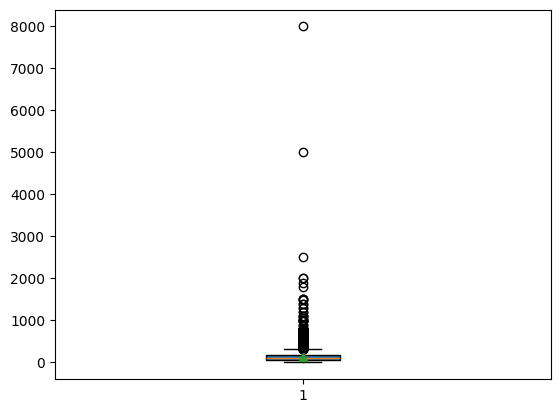

In [39]:
plt.boxplot(copy['Price'], showmeans=True, patch_artist=True)

plt.show()

### **After removing Outliers**

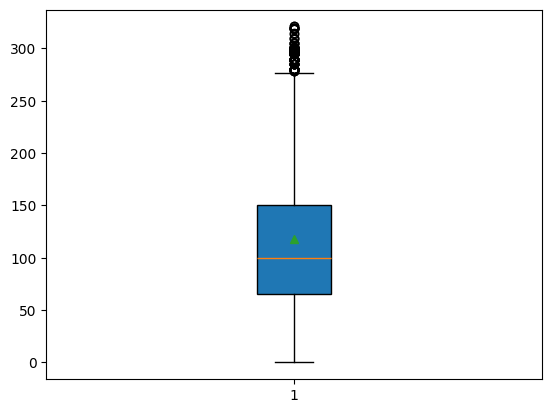

In [40]:
plt.boxplot(cleaned['Price'], showmeans=True, patch_artist=True)

plt.show()

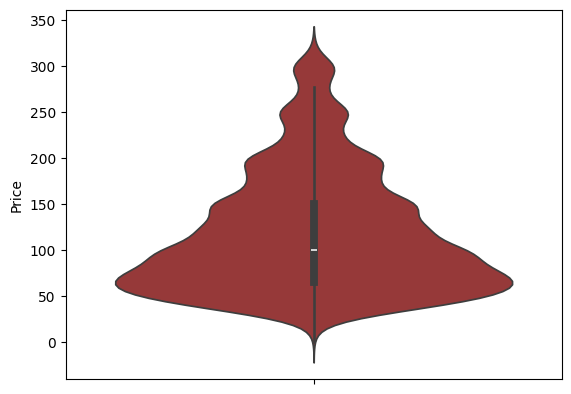

In [41]:
sns.violinplot(cleaned['Price'], color='brown')
plt.show()

### **Price Distribution Plot**

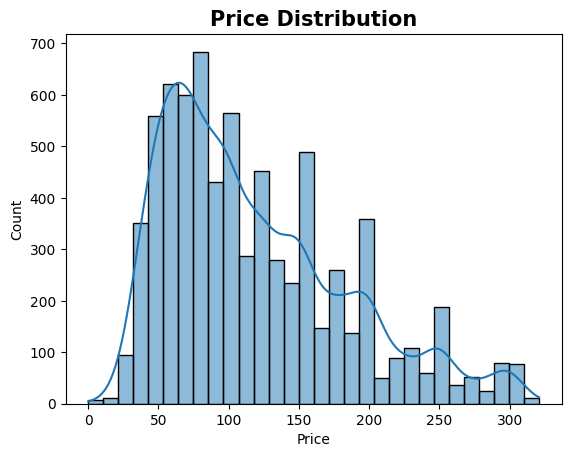

In [42]:
sns.histplot(cleaned['Price'], bins=30, kde=True)
plt.title("Price Distribution", fontsize=15, fontweight='bold')
plt.show()

### **Availability Distribution Plot**

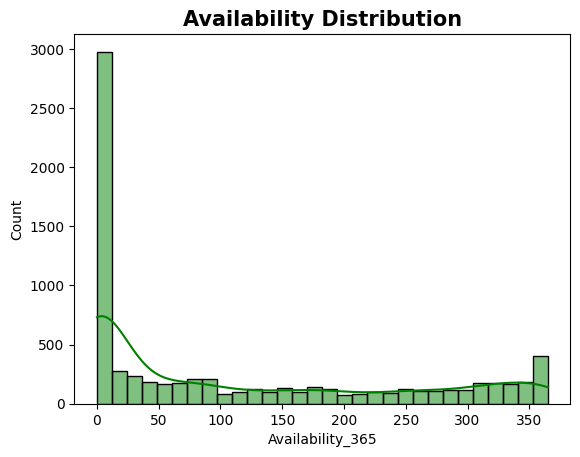

In [43]:
sns.histplot(cleaned['Availability_365'], bins=30, kde=True, color='green')
plt.title("Availability Distribution", fontsize=15, fontweight='bold')
plt.show()

### **Rating Distribution Plot**

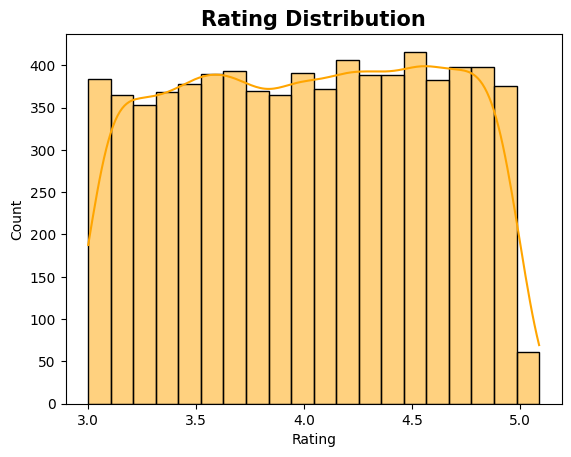

In [44]:
sns.histplot(cleaned['Rating'], bins=20, kde=True,color='orange')
plt.title("Rating Distribution", fontsize=15, fontweight='bold')
plt.show()

### **Number of Stays Distribution Plot**

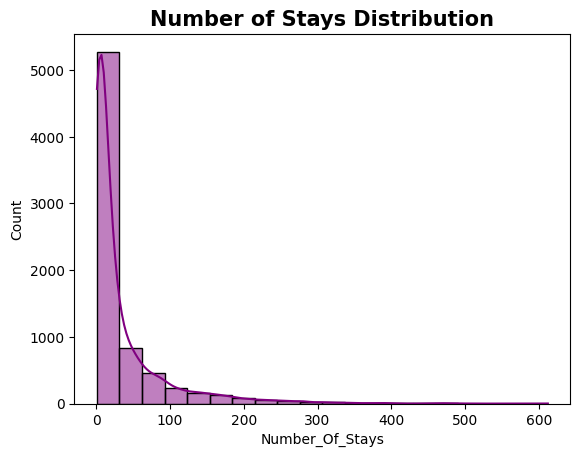

In [45]:
sns.histplot(cleaned['Number_Of_Stays'], bins=20, kde=True, color='purple')
plt.title("Number of Stays Distribution", fontsize=15, fontweight='bold')
plt.show()

## **Categorical Plots**

C:\Users\yashk\AppData\Local\Temp\ipykernel_27572\1870612975.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=cleaned, x='Room_Type', palette='Set2')


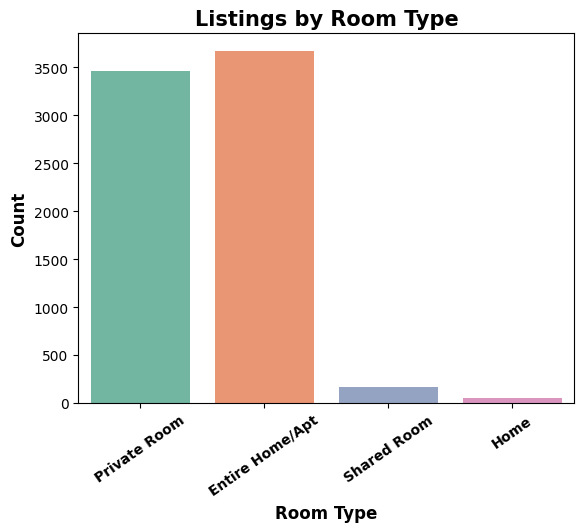

In [46]:
sns.countplot(data=cleaned, x='Room_Type', palette='Set2')
plt.title("Listings by Room Type", fontsize=15, fontweight='bold')
plt.xticks(rotation=35, color='black',  fontweight='bold')
plt.xlabel("Room Type", fontsize=12, fontweight='bold')
plt.ylabel("Count", fontsize=12, fontweight='bold')
plt.show()

C:\Users\yashk\AppData\Local\Temp\ipykernel_27572\1452666694.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=cleaned, x='Room_Type', y='Price', estimator='mean', ci=None, palette='Set1')
C:\Users\yashk\AppData\Local\Temp\ipykernel_27572\1452666694.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cleaned, x='Room_Type', y='Price', estimator='mean', ci=None, palette='Set1')


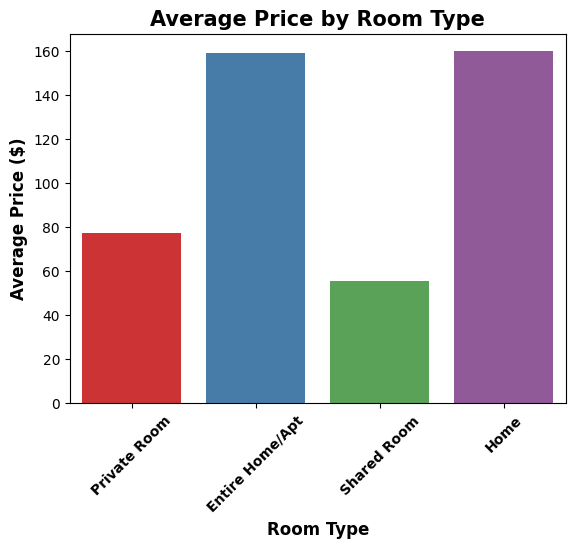

In [47]:
sns.barplot(data=cleaned, x='Room_Type', y='Price', estimator='mean', ci=None, palette='Set1')
plt.title("Average Price by Room Type", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, fontweight='bold')
plt.xlabel("Room Type", fontsize=12, fontweight='bold')
plt.ylabel("Average Price ($)", fontsize=12, fontweight='bold')
plt.show()

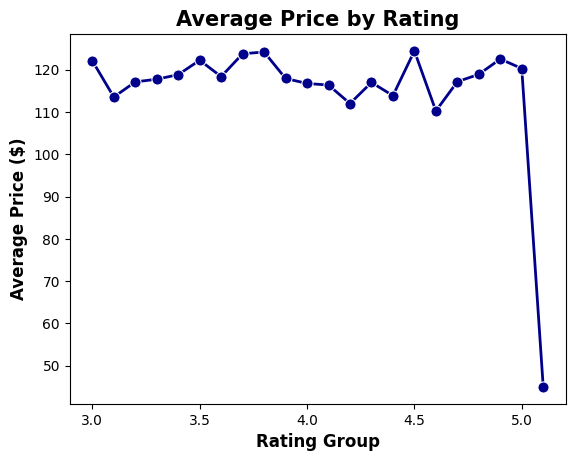

In [48]:
cleaned["Rating_Group"] = cleaned["Rating"].round(1)

sns.lineplot(
    data=cleaned,
    x="Rating_Group",
    y="Price",
    estimator="mean",
    errorbar=None,
    marker="o",
    color="darkblue",
    linewidth=2,
    ms=8
)

plt.title("Average Price by Rating", fontsize=15, fontweight='bold')
plt.xlabel("Rating Group", fontsize=12, fontweight='bold')
plt.ylabel("Average Price ($)", fontsize=12, fontweight='bold')
plt.show()

### **Neighborhood analysis**

C:\Users\yashk\AppData\Local\Temp\ipykernel_27572\1998884941.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette='Set2')


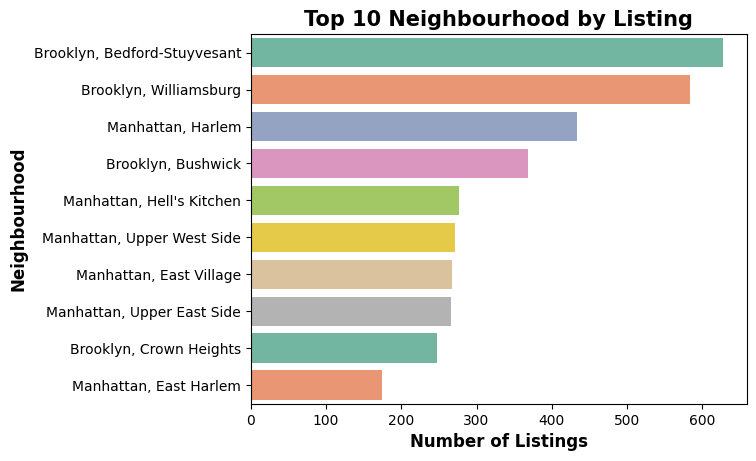

In [49]:
top10 = cleaned['Neighbourhood_Full'].value_counts().head(10)

sns.barplot(x=top10.values, y=top10.index, palette='Set2')
plt.title("Top 10 Neighbourhood by Listing", fontsize=15, fontweight='bold')
plt.xlabel("Number of Listings", fontsize=12, fontweight='bold')
plt.ylabel("Neighbourhood", fontsize=12, fontweight='bold')
plt.show()

C:\Users\yashk\AppData\Local\Temp\ipykernel_27572\2311681538.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


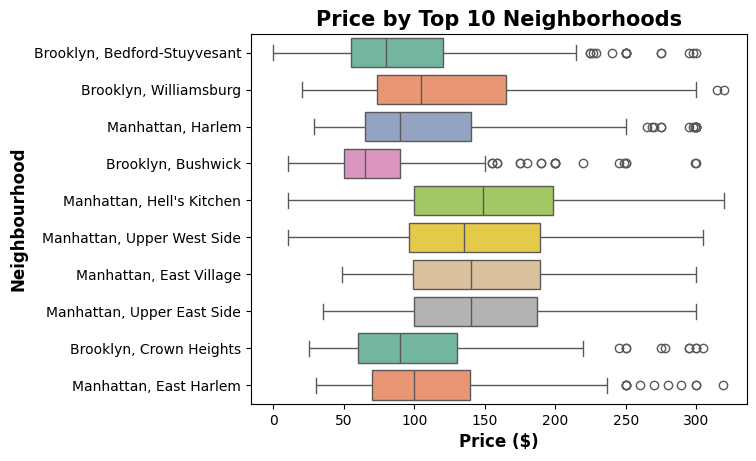

In [50]:
top10_names = cleaned["Neighbourhood_Full"].value_counts().head(10).index

sns.boxplot(
    data=cleaned[cleaned["Neighbourhood_Full"].isin(top10_names)],
    x="Price",
    y="Neighbourhood_Full",
    order=top10_names,
    palette='Set2'
)

plt.title("Price by Top 10 Neighborhoods", fontsize=15, fontweight='bold')
plt.xlabel("Price ($)", fontsize=12, fontweight='bold')
plt.ylabel("Neighbourhood", fontsize=12, fontweight='bold')
plt.show()

### **Relationship Analysis**

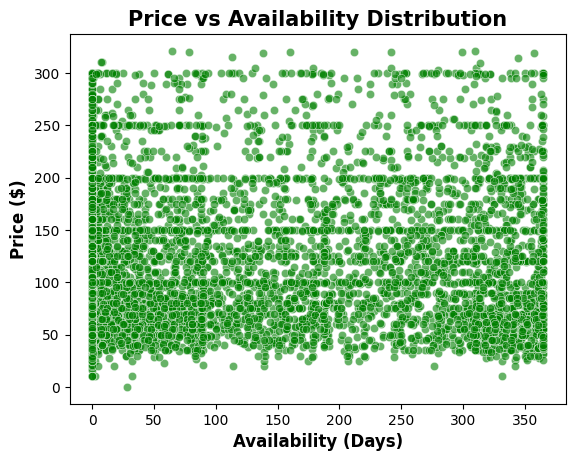

In [51]:
sns.scatterplot(
    data=cleaned,
    x = 'Availability_365',
    y = 'Price',
    color='green',
    alpha=0.6
)
plt.title("Price vs Availability Distribution", fontsize=15, fontweight='bold')
plt.xlabel("Availability (Days)", fontsize=12, fontweight='bold')
plt.ylabel("Price ($)", fontsize=12, fontweight='bold')
plt.show()

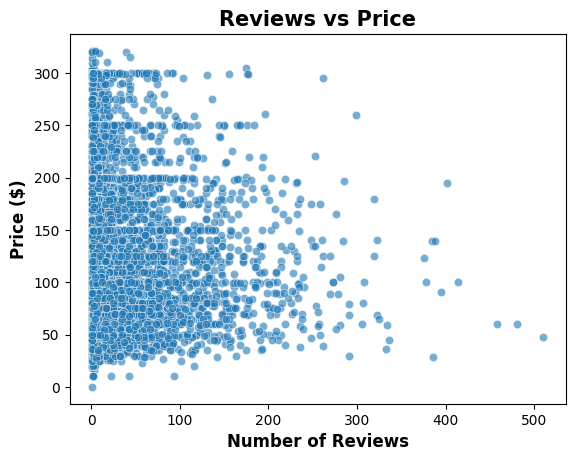

In [52]:
sns.scatterplot(
    data=cleaned,
    x='Number_Of_Reviews',
    y='Price',
    alpha=0.6,
)
plt.title("Reviews vs Price", fontsize=15, fontweight='bold')
plt.xlabel("Number of Reviews", fontsize=12, fontweight='bold')
plt.ylabel("Price ($)", fontsize=12, fontweight='bold')
plt.show()

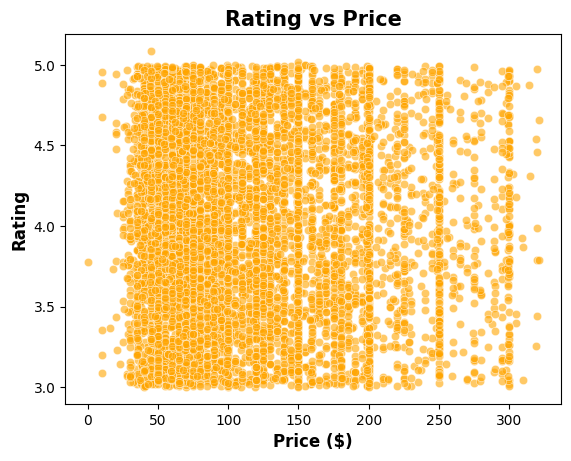

In [53]:
sns.scatterplot(
    data=cleaned,
    x='Price',
    y='Rating',
    alpha=0.6,
    color='orange'
)
plt.title("Rating vs Price", fontsize=15, fontweight='bold')
plt.xlabel("Price ($)", fontsize=12, fontweight='bold')
plt.ylabel("Rating", fontsize=12, fontweight='bold')
plt.show()

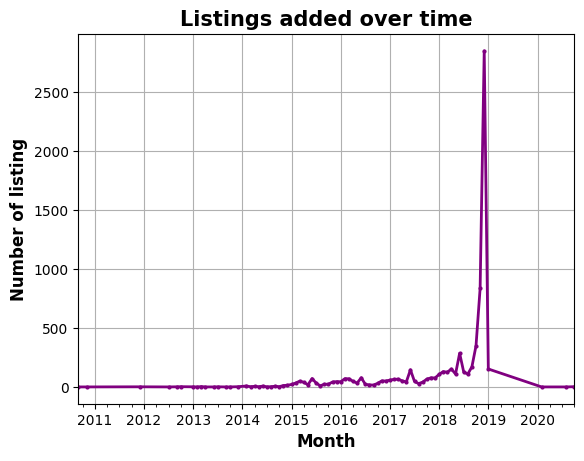

In [54]:
cleaned['Listing_Added'].dt.to_period('M').value_counts().sort_index().plot(linewidth=2, marker='o', color='purple', markersize=2)

plt.title("Listings added over time", fontsize=15, fontweight='bold')
plt.xlabel("Month", fontsize=12, fontweight='bold')
plt.ylabel("Number of listing", fontsize=12, fontweight='bold')
plt.grid(True)
plt.show()

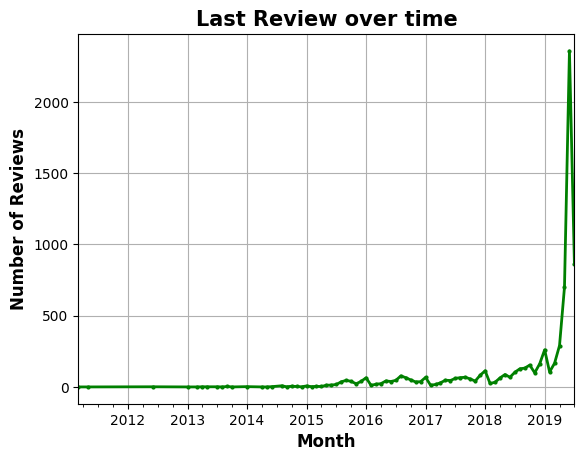

In [55]:
cleaned['Last_Review'].dt.to_period('M').value_counts().sort_index().plot(color='green', linewidth=2, grid=True, marker='o', markersize=2)

plt.title("Last Review over time", fontsize=15, fontweight='bold')
plt.xlabel("Month", fontsize=12, fontweight='bold')
plt.ylabel("Number of Reviews", fontsize=12, fontweight='bold')
plt.show()

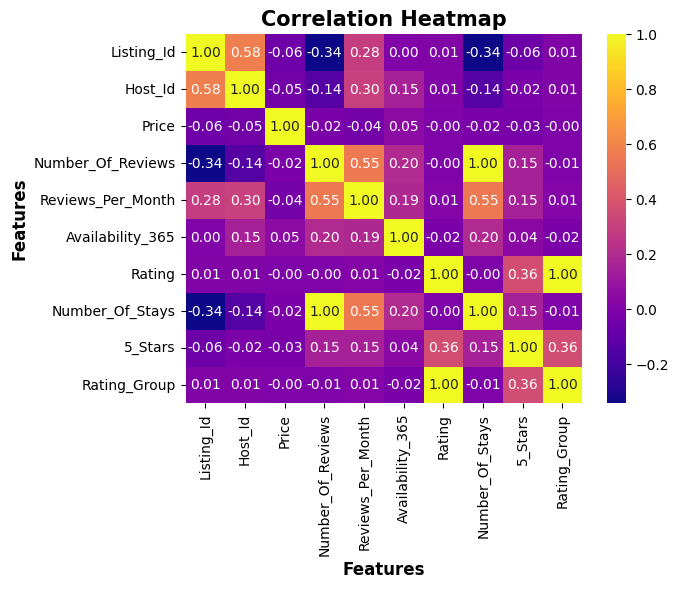

In [56]:
numeric_df = cleaned.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='plasma',
    fmt=".2f",
)

plt.title("Correlation Heatmap", fontsize=15, fontweight='bold')
plt.xlabel("Features", fontsize=12, fontweight='bold')
plt.ylabel("Features", fontsize=12, fontweight='bold')
plt.show()

### **3D Plot**

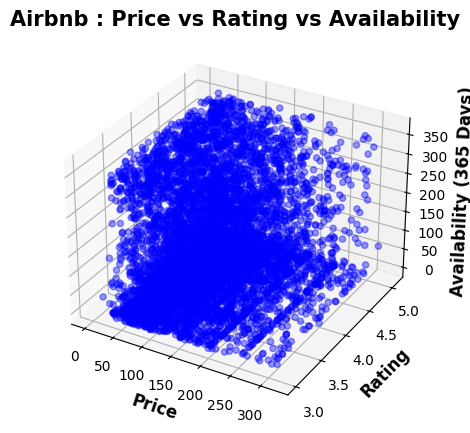

In [57]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    cleaned["Price"],
    cleaned["Rating"],
    cleaned["Availability_365"],
    alpha=0.4,
    marker='o',
    color='blue',
)

ax.set_xlabel("Price", fontsize=12, fontweight='bold')
ax.set_ylabel("Rating", fontsize=12, fontweight='bold')
ax.set_zlabel("Availability (365 Days)", fontsize=12, fontweight='bold')

ax.set_title("Airbnb : Price vs Rating vs Availability", fontsize=15, fontweight='bold')

plt.show()